In [5]:
import spikeinterface.extractors as se
recording = se.read_maxwell(".\Development_2953_5month.raw.h5")

The h5 compression library for Maxwell is already located in C:\Users\Bin\hdf5_plugin_path_maxwell\compression.dll!


In [6]:
print(recording)
locations = recording.get_channel_locations()

print(locations.shape)
print(locations[:5])

MaxwellRecordingExtractor: 1020 channels - 20.0kHz - 1 segments - 3,596,600 samples 
                           179.83s (3.00 minutes) - uint16 dtype - 6.83 GiB
  file_path: d:\data_analysis\pre_exp2026928\pre_exp\Development_2953_5month.raw.h5
(1020, 2)
[[1592.5  857.5]
 [3552.5 1172.5]
 [ 612.5  997.5]
 [2922.5 1032.5]
 [1102.5 1032.5]]


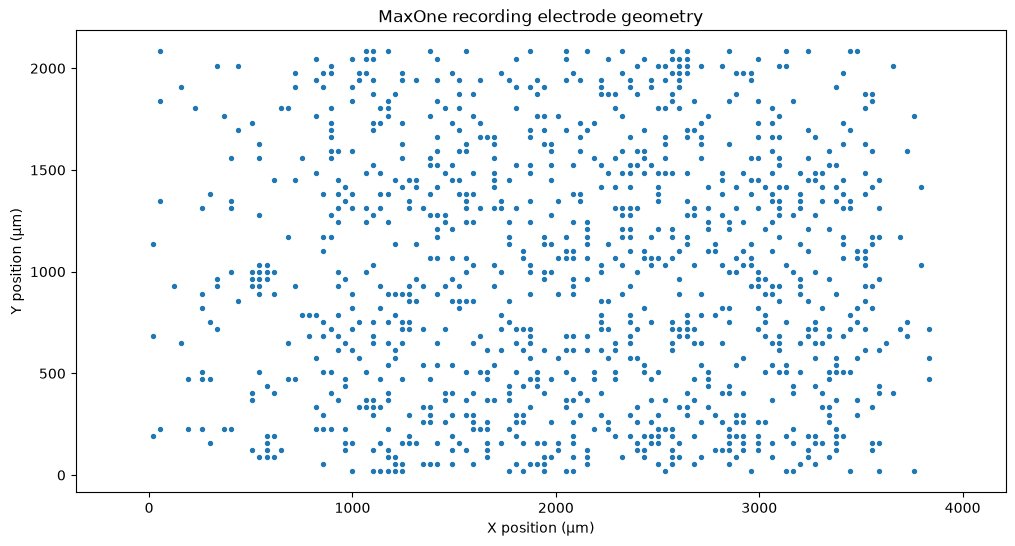

In [7]:
import matplotlib.pyplot as plt

locations = recording.get_channel_locations()

plt.figure(figsize=(12, 6))

plt.scatter(
    locations[:, 0],
    locations[:, 1],
    s=8
)

plt.xlabel("X position (µm)")
plt.ylabel("Y position (µm)")
plt.title("MaxOne recording electrode geometry")

plt.axis("equal")
plt.show()

In [8]:
print("SpikeInterface properties:")
print(recording.get_property_keys())
print(recording.get_dtype)

SpikeInterface properties:
['gain_to_uV', 'offset_to_uV', 'physical_unit', 'gain_to_physical_unit', 'offset_to_physical_unit', 'channel_name', 'group', 'electrode']
<bound method BaseRecordingSnippets.get_dtype of MaxwellRecordingExtractor: 1020 channels - 20.0kHz - 1 segments - 3,596,600 samples 
                           179.83s (3.00 minutes) - uint16 dtype - 6.83 GiB
  file_path: d:\data_analysis\pre_exp2026928\pre_exp\Development_2953_5month.raw.h5>


In [9]:
import numpy as np
print("physical_unit:")
print(np.unique(recording.get_property("physical_unit")))

print("\ngain_to_uV:")
print(np.unique(recording.get_property("gain_to_uV")))

print("\noffset_to_uV:")
print(np.unique(recording.get_property("offset_to_uV")))

print("\nelectrode:")
print(recording.get_property("electrode")[:20])

physical_unit:
['uV']

gain_to_uV:
[6.29425]

offset_to_uV:
[0.]

electrode:
[10871 14943 12575 13147 13043 14951 10881 12283 14301 17129 12629 16237
 12563  9673 13071 14503  9103 13181 11691 16683]


In [10]:
import pandas as pd

channel_ids = recording.get_channel_ids()
electrodes = recording.get_property("electrode")
locations = recording.get_channel_locations()

channel_map = pd.DataFrame({
    "channel_id": channel_ids,
    "electrode_id": electrodes,
    "x_um": locations[:, 0],
    "y_um": locations[:, 1]
})

display(channel_map.head(20))

,channel_id,electrode_id,x_um,y_um
0,0,10871,1592.5,857.5
1,1,14943,3552.5,1172.5
2,2,12575,612.5,997.5
3,3,13147,2922.5,1032.5
4,4,13043,1102.5,1032.5
5,5,14951,3692.5,1172.5
6,6,10881,1767.5,857.5
7,7,12283,3202.5,962.5
8,8,14301,17.5,1137.5
9,9,17129,3307.5,1347.5


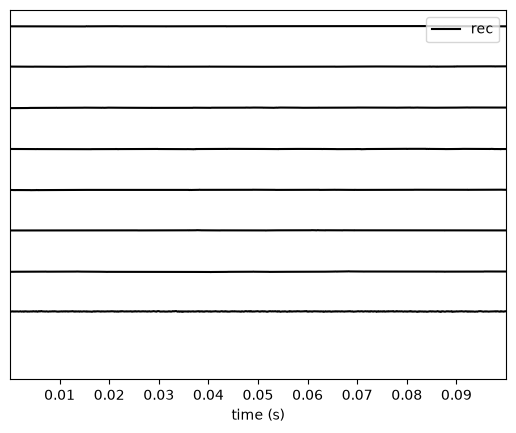

In [11]:
import matplotlib.pyplot as plt
import spikeinterface.widgets as sw

# 显示 0~1 s 的原始多通道数据
sw.plot_traces(
    recording,
    time_range=(0,0.1),
    mode="line",
    return_in_uV=True,
    channel_ids=['0', '1', '2', '3', '4', '5', '6', '7']
)

plt.show()

In [12]:
print(recording)

print("Sampling frequency:",
      recording.get_sampling_frequency())

print("Channels:",
      recording.get_channel_ids())

print("Number of channels:",
      recording.get_num_channels())

print("Duration:",
      recording.get_total_duration())

print("Properties:",
      recording.get_property_keys())

print("Locations:")
print(recording.get_channel_locations())

MaxwellRecordingExtractor: 1020 channels - 20.0kHz - 1 segments - 3,596,600 samples 
                           179.83s (3.00 minutes) - uint16 dtype - 6.83 GiB
  file_path: d:\data_analysis\pre_exp2026928\pre_exp\Development_2953_5month.raw.h5
Sampling frequency: 20000.0
Channels: ['0' '1' '2' ... '1021' '1022' '1023']
Number of channels: 1020
Duration: 179.82999999999998
Properties: ['gain_to_uV', 'offset_to_uV', 'physical_unit', 'gain_to_physical_unit', 'offset_to_physical_unit', 'channel_name', 'group', 'electrode']
Locations:
[[1592.5  857.5]
 [3552.5 1172.5]
 [ 612.5  997.5]
 ...
 [2397.5  332.5]
 [2117.5 1662.5]
 [2502.5 1417.5]]


In [13]:
#检查物理单位和电极信息
import numpy as np

print("=== Recording ===")
print(recording)

print("\n=== Units ===")
print("physical_unit:",
      np.unique(recording.get_property("physical_unit")))
print("gain_to_uV:",
      np.unique(recording.get_property("gain_to_uV")))
print("offset_to_uV:",
      np.unique(recording.get_property("offset_to_uV")))

print("\n=== Geometry ===")
locations = recording.get_channel_locations()
electrodes = recording.get_property("electrode")

print("locations shape:", locations.shape)
print("electrodes shape:", electrodes.shape)

print("\nFirst 10 electrodes:")
print(electrodes[:10])

print("\nFirst 10 locations:")
print(locations[:10])

=== Recording ===
MaxwellRecordingExtractor: 1020 channels - 20.0kHz - 1 segments - 3,596,600 samples 
                           179.83s (3.00 minutes) - uint16 dtype - 6.83 GiB
  file_path: d:\data_analysis\pre_exp2026928\pre_exp\Development_2953_5month.raw.h5

=== Units ===
physical_unit: ['uV']
gain_to_uV: [6.29425]
offset_to_uV: [0.]

=== Geometry ===
locations shape: (1020, 2)
electrodes shape: (1020,)

First 10 electrodes:
[10871 14943 12575 13147 13043 14951 10881 12283 14301 17129]

First 10 locations:
[[1592.5  857.5]
 [3552.5 1172.5]
 [ 612.5  997.5]
 [2922.5 1032.5]
 [1102.5 1032.5]
 [3692.5 1172.5]
 [1767.5  857.5]
 [3202.5  962.5]
 [  17.5 1137.5]
 [3307.5 1347.5]]


In [14]:
import spikeinterface.sorters as ss

print("Kilosort4 installed:")
print(ss.Kilosort4Sorter.is_installed())

params = ss.get_default_sorter_params("kilosort4")

for key, value in params.items():
    print(f"{key}: {value}")

Kilosort4 installed:
False
pool_engine: process
n_jobs: 1
chunk_duration: 1s
progress_bar: True
mp_context: None
max_threads_per_worker: 1


c:\Users\Bin\miniconda3\envs\spike_sort\Lib\site-packages\spikeinterface\sorters\external\kilosort4.py:112: UserWarning: Kilosort4 is not installed. Please install kilosort4 to get the parameters.
  warnings.warn("Kilosort4 is not installed. Please install kilosort4 to get the parameters.")


In [15]:
import numpy as np

locations = recording.get_channel_locations()
channel_ids = recording.get_channel_ids()

# 以第 0 个电极为中心
center = locations[0]

distance = np.linalg.norm(
    locations - center,
    axis=1
)

nearest_indices = np.argsort(distance)[:32]

selected_channels = channel_ids[nearest_indices]

recording_test = (
    recording
    .select_channels(selected_channels)
    .time_slice(start_time=0, end_time=30)
)

print(recording_test)
print(recording_test.get_channel_locations())

FrameSliceRecording: 32 channels - 20.0kHz - 1 segments - 600,000 samples - 30.00s - uint16 dtype 
                     36.62 MiB
[[1592.5  857.5]
 [1557.5  857.5]
 [1522.5  857.5]
 [1522.5  822.5]
 [1522.5  927.5]
 [1487.5  857.5]
 [1697.5  927.5]
 [1557.5  997.5]
 [1487.5  962.5]
 [1452.5  927.5]
 [1732.5  787.5]
 [1767.5  857.5]
 [1592.5 1032.5]
 [1417.5  892.5]
 [1627.5  682.5]
 [1732.5  717.5]
 [1452.5  717.5]
 [1732.5  997.5]
 [1697.5 1032.5]
 [1767.5  752.5]
 [1592.5  647.5]
 [1557.5 1067.5]
 [1487.5 1067.5]
 [1802.5  717.5]
 [1662.5  612.5]
 [1347.5  927.5]
 [1417.5 1067.5]
 [1417.5  647.5]
 [1312.5  857.5]
 [1732.5  612.5]
 [1837.5  717.5]
 [1872.5  892.5]]


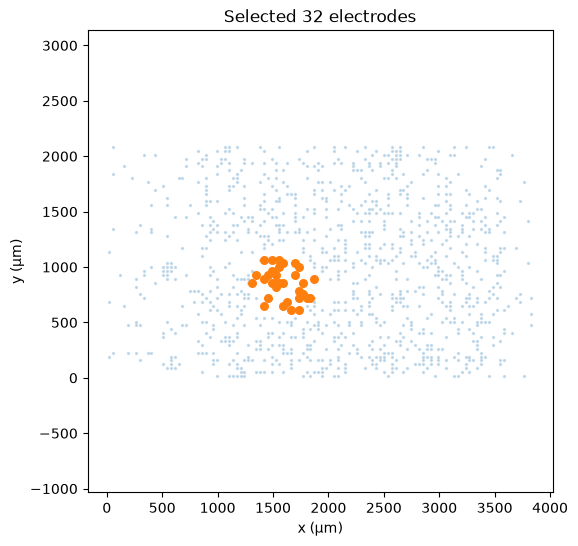

In [16]:
import matplotlib.pyplot as plt

test_locations = recording_test.get_channel_locations()

plt.figure(figsize=(6, 6))

plt.scatter(
    locations[:, 0],
    locations[:, 1],
    s=2,
    alpha=0.2
)

plt.scatter(
    test_locations[:, 0],
    test_locations[:, 1],
    s=30
)

plt.xlabel("x (µm)")
plt.ylabel("y (µm)")
plt.axis("equal")
plt.title("Selected 32 electrodes")

plt.show()

In [17]:
import spikeinterface.sorters as ss

print(
    "MountainSort5:",
    ss.Mountainsort5Sorter.is_installed()
)

MountainSort5: True


In [18]:
sorting_test = ss.run_sorter(
    sorter_name="mountainsort5",
    recording=recording_test,
    folder="mountainsort5_test",
    remove_existing_folder=True,
    verbose=True
)

The h5 compression library for Maxwell is already located in C:\Users\Bin\hdf5_plugin_path_maxwell\compression.dll!
filtering
whitening


write_binary (no parallelization): 100%|██████████| 30/30 [00:04<00:00,  6.07it/s]


Using training recording of duration 300 sec with the sampling mode uniform
*** MS5 Elapsed time for SCHEME2 get_sampled_recording_for_training: 0.000 seconds ***
Running phase 1 sorting
Number of channels: 32
Number of timepoints: 600000
Sampling frequency: 20000.0 Hz
Channel 0: [1592.5  857.5]
Channel 1: [1557.5  857.5]
Channel 2: [1522.5  857.5]
Channel 3: [1522.5  822.5]
Channel 4: [1522.5  927.5]
Channel 5: [1487.5  857.5]
Channel 6: [1697.5  927.5]
Channel 7: [1557.5  997.5]
Channel 8: [1487.5  962.5]
Channel 9: [1452.5  927.5]
Channel 10: [1732.5  787.5]
Channel 11: [1767.5  857.5]
Channel 12: [1592.5 1032.5]
Channel 13: [1417.5  892.5]
Channel 14: [1627.5  682.5]
Channel 15: [1732.5  717.5]
Channel 16: [1452.5  717.5]
Channel 17: [1732.5  997.5]
Channel 18: [1697.5 1032.5]
Channel 19: [1767.5  752.5]
Channel 20: [1592.5  647.5]
Channel 21: [1557.5 1067.5]
Channel 22: [1487.5 1067.5]
Channel 23: [1802.5  717.5]
Channel 24: [1662.5  612.5]
Channel 25: [1347.5  927.5]
Channel 26: 

In [19]:
print(sorting_test)

unit_ids = sorting_test.get_unit_ids()

print("Number of units:", len(unit_ids))
print("Unit IDs:", unit_ids)

NpzSortingExtractor: 0 units - 1 segments - 20.0kHz
  file_path: d:\data_analysis\pre_exp2026928\pre_exp\mountainsort5_test\sorter_output\firings.npz
Number of units: 0
Unit IDs: []


In [20]:
fs = recording_test.get_sampling_frequency()

for unit_id in unit_ids[:5]:

    spike_samples = sorting_test.get_unit_spike_train(
        unit_id=unit_id
    )

    spike_times = spike_samples / fs

    print(
        f"Unit {unit_id}: "
        f"{len(spike_samples)} spikes"
    )

    print(
        "First spike times:",
        spike_times[:10]
    )

In [21]:
import spikeinterface as si

analyzer = si.create_sorting_analyzer(
    sorting=sorting_test,
    recording=recording_test,
    format="memory"
)

print(analyzer)

SortingAnalyzer: 32 channels - 0 units - 1 segments - memory - sparse - has recording
Loaded 0 extensions


In [22]:
analyzer.compute(
    "random_spikes",
    max_spikes_per_unit=500
)

analyzer.compute(
    "waveforms",
    ms_before=1.0,
    ms_after=2.0
)

print(analyzer)

SortingAnalyzer: 32 channels - 0 units - 1 segments - memory - sparse - has recording
Loaded 2 extensions: random_spikes, waveforms


In [25]:
analyzer.compute("templates")

In [26]:
print(analyzer)

SortingAnalyzer: 32 channels - 0 units - 1 segments - memory - sparse - has recording
Loaded 3 extensions: random_spikes, waveforms, templates


In [ ]:
import spikeinterface.widgets as sw
import matplotlib.pyplot as plt

sw.plot_unit_templates(
    analyzer,
    channel_ids=recording_test.get_channel_ids(),
    unit_ids=unit_ids
)

plt.show()

ValueError: zero-size array to reduction operation maximum which has no identity

<Figure size 640x480 with 0 Axes>

In [ ]:
import numpy as np
from scipy.signal import butter, sosfiltfilt

def bandpass_filter(x, fs, low=300, high=6000, order=4):
    sos = butter(
        order,
        [low, high],
        btype="bandpass",
        fs=fs,
        output="sos"
    )
    return sosfiltfilt(sos, x, axis=0)


# 1. 只读取一次
channel_ids = ['0', '1', '2', '3', '4', '5', '6', '7']
traces = recording.get_traces(channel_ids=channel_ids)   # 形状: (num_samples, 8)

# 2. 去直流（每个通道单独减均值）
traces = traces - np.mean(traces, axis=0)

# 3. 滤波
fs = recording.get_sampling_frequency()
filtered_traces = bandpass_filter(traces, fs)

print("原始数据:", traces.shape)
print("滤波数据:", filtered_traces.shape)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from matplotlib.ticker import MaxNLocator

# =========================
# 参数
# =========================
start_time = 10      # 起始时间，s
end_time = 10.1      # 结束时间，s

# 获取采样率
fs = recording.get_sampling_frequency()

# 获取全部通道
#channel_ids = recording.get_channel_ids()
channel_ids=['0', '1', '2', '3', '4', '5', '6', '7']

# 时间转换为采样点
start_frame = int(start_time * fs)
end_frame = int(end_time * fs)

# 提取原始数据
# shape = (n_samples, n_channels)
traces = recording.get_traces(
    start_frame=start_frame,
    end_frame=end_frame,
    channel_ids=channel_ids
)

# 构造时间轴
time = np.arange(traces.shape[0]) / fs + start_time

# =========================
# 每个 channel 单独绘图
# =========================
for i, ch in enumerate(channel_ids):

    fig, ax = plt.subplots(figsize=(12, 2.5), dpi=150)
    plt.rcParams.update({'font.sans-serif': 'Arial'})
    ax.plot(
        time,
        filtered_traces[:, i],
        linewidth=0.3,
        color="black"
    )

    ax.set_title(f"Channel {ch}",fontsize=12)
    ax.set_xlabel("Time (s)",fontsize=12)
    ax.set_ylabel("Amplitude (μV)",fontsize=12)

    ax.set_xlim(start_time, end_time)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.0)
    ax.spines["bottom"].set_linewidth(1.0)
    ax.grid(False)
    ax.xaxis.set_major_locator(MultipleLocator(0.02)) # x轴间隔0.02
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4, integer=True))  # 只取整数
    ax.tick_params(
    axis="both",             # "x" / "y" / "both"
    which="major",           # "major" / "minor" / "both"
    labelsize=10,            # ★ 刻度标签字号
    labelcolor="#333333",    # 标签颜色
    labelrotation=0,         # 标签旋转
    pad=4,                   # 标签与刻度线间距
    direction="in",          # 刻度线方向
    length=5,                # 刻度线长度
    width=1.0,               # 刻度线粗细
    color="#333333",       # 刻度线颜色
    top=False,               # 顶部刻度
    right=False,             # 右侧刻度
    bottom=True,              # 底部刻度    
    left=True,                # 左侧刻度    
    )
    plt.tight_layout()
    plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, MaxNLocator
from scipy.signal import butter, sosfiltfilt


# =========================
# 滤波函数
# =========================
def bandpass_filter(x, fs, low=300, high=6000, order=4):
    sos = butter(order, [low, high], btype="bandpass", fs=fs, output="sos")
    return sosfiltfilt(sos, x, axis=0)


# =========================
# 参数
# =========================
start_time = 10        # 起始时间，s
end_time = 10.1       # 结束时间，s

fs = recording.get_sampling_frequency()
channel_ids = ['0', '1', '2', '3', '4', '5', '6', '7']

start_frame = int(start_time * fs)
end_frame = int(end_time * fs)

# =========================
# 提取原始数据 (n_samples, n_channels)
# =========================
traces = recording.get_traces(
    start_frame=start_frame,
    end_frame=end_frame,
    channel_ids=channel_ids,
    return_in_uV=True
)

# =========================
# 去直流 + 滤波
# =========================
traces = traces - np.mean(traces, axis=0)           # 每通道单独减均值
filtered_traces = bandpass_filter(traces, fs)       # 带通滤波

# 构造时间轴（与 filtered_traces 长度一致）
time = np.arange(filtered_traces.shape[0]) / fs + start_time

# =========================
# 每个 channel 单独绘图
# =========================
plt.rcParams.update({'font.sans-serif': 'Arial'})

for i, ch in enumerate(channel_ids):
    fig, ax = plt.subplots(figsize=(12, 2.5), dpi=150)

    ax.plot(
        time,
        filtered_traces[:, i],
        linewidth=0.3,
        color="black"
    )

    ax.set_title(f"Channel {ch}", fontsize=12)
    ax.set_xlabel("Time (s)", fontsize=12)
    ax.set_ylabel("Amplitude (μV)", fontsize=12)

    ax.set_xlim(start_time, end_time)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.0)
    ax.spines["bottom"].set_linewidth(1.0)
    ax.grid(False)

    ax.xaxis.set_major_locator(MultipleLocator(0.02))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4, integer=True))

    ax.tick_params(
        axis="both",
        which="major",
        labelsize=10,
        labelcolor="#333333",
        labelrotation=0,
        pad=4,
        direction="in",
        length=5,
        width=1.0,
        color="#333333",
        top=False,
        right=False,
        bottom=True,
        left=True,
    )

    plt.tight_layout()
    plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, MaxNLocator
from scipy.signal import butter, sosfiltfilt


# =========================
# 滤波函数
# =========================
def bandpass_filter(x, fs, low=300, high=6000, order=4):
    sos = butter(order, [low, high], btype="bandpass", fs=fs, output="sos")
    return sosfiltfilt(sos, x, axis=0)


# =========================
# 参数（继承你之前的设置）
# =========================
start_time = 10        # 起始时间，s
end_time = 10.1        # 结束时间，s

fs = recording.get_sampling_frequency()
channel_ids = ['0', '1', '2', '3', '4', '5', '6', '7']

start_frame = int(start_time * fs)
end_frame = int(end_time * fs)

# =========================
# 提取原始数据 (n_samples, n_channels)
# =========================
traces = recording.get_traces(
    start_frame=start_frame,
    end_frame=end_frame,
    channel_ids=channel_ids
)

# =========================
# 去直流 + 滤波
# =========================
traces = traces - np.mean(traces, axis=0)           # 每通道单独减均值
filtered_traces = bandpass_filter(traces, fs)       # 带通滤波

# 构造时间轴（与 filtered_traces 长度一致）
time = np.arange(filtered_traces.shape[0]) / fs + start_time


# =========================
# SNR 估算函数
# =========================
def estimate_noise_sigma(x):
    """用 MAD 估计噪声标准差，x 为一维数组"""
    median = np.median(x)
    mad = np.median(np.abs(x - median))
    sigma = mad / 0.6745
    return median, mad, sigma


def estimate_snr_by_threshold(x, sigma, k=4.0):
    """
    用阈值法粗略估计 SNR：
    - 超过 k*sigma 的峰值视为候选 spike
    - SNR ≈ 峰值幅度 / sigma
    """
    threshold = k * sigma
    pos_peaks = x[x > threshold]
    neg_peaks = x[x < -threshold]

    if len(pos_peaks) == 0 and len(neg_peaks) == 0:
        return 0.0, 0, 0.0

    max_pos = np.max(pos_peaks) if len(pos_peaks) > 0 else 0.0
    max_neg = np.min(neg_peaks) if len(neg_peaks) > 0 else 0.0

    amplitude = max(max_pos, abs(max_neg))
    snr = amplitude / sigma

    return snr, len(pos_peaks) + len(neg_peaks), amplitude


# =========================
# 对每个通道计算噪声和 SNR
# =========================
n_channels = filtered_traces.shape[1]

print(f"{'Ch':>4} {'Median':>10} {'MAD':>10} {'Sigma':>10} "
      f"{'SNR(4σ)':>10} {'#Peaks>4σ':>10} {'Amp':>10}")
print("-" * 70)

for i, ch in enumerate(channel_ids):
    x = filtered_traces[:, i]
    median, mad, sigma = estimate_noise_sigma(x)
    snr, n_peaks, amp = estimate_snr_by_threshold(x, sigma, k=4.0)

    print(f"{ch:>4} {median:>10.3f} {mad:>10.3f} {sigma:>10.3f} "
          f"{snr:>10.2f} {n_peaks:>10d} {amp:>10.3f}")


# =========================
# 不同阈值下的 SNR（以通道 0 为例）
# =========================
print("\n不同阈值下的 SNR（以通道 0 为例）：")
x = filtered_traces[:, 0]
_, _, sigma = estimate_noise_sigma(x)

for k in [3, 3.5, 4, 4.5, 5, 5.5, 6]:
    snr, n_peaks, amp = estimate_snr_by_threshold(x, sigma, k=k)
    print(f"  {k:3.1f}σ: 阈值 ±{k*sigma:6.2f} μV, "
          f"峰值幅度 {amp:6.2f} μV, SNR ≈ {snr:5.2f}, 峰数 {n_peaks}")


# =========================
# 可选：把阈值线画到图上
# =========================
plt.rcParams.update({'font.sans-serif': 'Arial'})

for i, ch in enumerate(channel_ids):
    fig, ax = plt.subplots(figsize=(12, 2.5), dpi=150)

    x = filtered_traces[:, i]
    _, _, sigma = estimate_noise_sigma(x)
    threshold = 4.0 * sigma

    ax.plot(time, x, linewidth=0.3, color="black")
    ax.axhline(threshold, color="red", linewidth=0.6, linestyle="--")
    ax.axhline(-threshold, color="red", linewidth=0.6, linestyle="--")

    ax.set_title(f"Channel {ch}  (σ={sigma:.2f} μV, 4σ={threshold:.2f} μV)",
                 fontsize=12)
    ax.set_xlabel("Time (s)", fontsize=12)
    ax.set_ylabel("Amplitude (μV)", fontsize=12)

    ax.set_xlim(start_time, end_time)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.0)
    ax.spines["bottom"].set_linewidth(1.0)
    ax.grid(False)

    ax.xaxis.set_major_locator(MultipleLocator(0.02))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4))

    ax.tick_params(
        axis="both", which="major",
        labelsize=10, labelcolor="#333333", labelrotation=0,
        pad=4, direction="in", length=5, width=1.0,
        color="#333333", top=False, right=False,
        bottom=True, left=True,
    )

    plt.tight_layout()
    plt.show()